In [1]:
# Statistical analysis for the CT Hospital Boarding manuscript.

# Self-contained reproduction of every quantitative result in the manuscript:
#   - Cohort filter
#   - Predictor definitions (bed utilization, surgical intensity, nursing resources)
#   - Bivariate associations (Spearman + Pearson)
#   - Multivariable OLS with cluster-robust SE (n = 46 hospital-years)
#   - Variance inflation factors
#   - Hospital-averaged sensitivity (n = 23)
#   - Within-hospital change-score analysis (n = 23 paired)
#   - Bed utilization decomposition (sensitivity)

# Inputs:
#   - analytic_panel.csv  (one row per hospital × year, extracted from OHS Reports
#     400/450 plus the CT Boarding Workbook). 46 hospital-years after cohort filter.

# Initially Drafted By: Claude version ***

In [2]:
# Dependencies:
# matplotlib                3.11.0          py314haa95532_0
# numpy                     2.5.0           py314h650627e_0
# openpyxl                  3.1.5           py314h827c3e9_1
# pandas                    3.0.3           py314hf1216d0_0
# python                    3.14.6          hb107ab2_100_cp314
# scikit-learn              1.9.0           py314h9b39bef_0
# scipy                     1.18.0          py314h176032c_0
# seaborn                   0.13.2          py314haa95532_3

In [3]:
from pathlib import Path
import pandas as pd
import numpy as np
from scipy.stats import spearmanr, pearsonr, norm
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.regression.linear_model import OLS
import zipfile
import io
import os
import numpy as np
from scipy import stats
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import MinMaxScaler

In [4]:
boarding_data = pd.read_csv('./analysis_data/Raw Data/hospital_name_crosswalk.csv').join(pd.concat([
    pd.read_csv('./analysis_data/Raw Data/2024_boarding.csv'),
    pd.read_csv('./analysis_data/Raw Data/2025_boarding.csv')
]).set_index('hospital'), on='CCEP_name', how='left').set_index(['hospital_slug', 'year'])

In [5]:
import warnings
warnings.filterwarnings("ignore", category=UserWarning, module="openpyxl")
report_450_values = []
report_400_values = []
for hospital_slug in boarding_data.index.get_level_values('hospital_slug').unique():
    additional_data = pd.read_excel(f'./analysis_data/Raw Data/450 reports/report450_{hospital_slug}_2025.xlsx')\
        .set_axis(['LINE', 'DESCRIPTION', 'ACTUAL FY2024', 'ACTUAL FY2025', 'AMOUNT DIFFERENCE', '% DIFFERENCE'], axis=1)\
        .set_index('DESCRIPTION')
    for year in [2024, 2025]:
        report_450_values.append({
            'hospital_slug': hospital_slug,
            'year': year,
            'inpatient_surgical_cases': additional_data.loc['Inpatient Surgical Procedures', f'ACTUAL FY{year}'],
            'outpatient_surgical_cases': additional_data.loc['Outpatient Surgical Procedures', f'ACTUAL FY{year}'],
            'total_nursing_hours': additional_data.loc['Total Nursing FTEs', f'ACTUAL FY{year}']
        })
    additional_data = pd.read_excel(f'./analysis_data/Raw Data/400 reports/report400_{hospital_slug}_2025.xlsx', skiprows=8).set_axis([
                'LINE','Bed Type',
                'Patient Days_2024','Patient Days_2025',
                'Discharges_2024','Discharges_2025',
                'Admissions_2024','Admissions_2025',
                'Staffed Beds_2024','Staffed Beds_2025',
                'Available Beds_2024','Available Beds_2025',
                '13', '14', '15', '16'
    ], axis=1).set_index('Bed Type')
    for year in [2024, 2025]:
        report_400_values.append({
            'hospital_slug': hospital_slug,
            'year': year,
            'patient_days_medical_surgical': additional_data.loc['Adult Medical/Surgical', f'Patient Days_{year}'],
            'admissions_medical_surgical': additional_data.loc['Adult Medical/Surgical', f'Admissions_{year}'],
            'staffed_beds_medical_surgical': additional_data.loc['Adult Medical/Surgical', f'Staffed Beds_{year}'],
            'available_beds_medical_surgical': additional_data.loc['Adult Medical/Surgical', f'Available Beds_{year}'],
            'total_inpatient_days': additional_data.loc[additional_data[f'Patient Days_{year}'] > 0, f'Patient Days_{year}'].sum(),
        })
main_data = boarding_data.join(pd.DataFrame(report_450_values).set_index(['hospital_slug', 'year']), how='left')\
    .join(pd.DataFrame(report_400_values).set_index(['hospital_slug', 'year']), how='left')

In [6]:
main_data.drop(['ct-children-s-medical-center'], axis=0, inplace=True) # exclude CT Childrens (Bristol already excluded from cohort filter)

In [7]:
main_data.to_csv('./analysis_data/Processed Data/analytic_panel.csv', index=True)

In [8]:
# ============================================================
# 3. PREDICTOR DEFINITIONS (three pre-specified operational dimensions)
# ============================================================
# Bed utilization: med/surg patient days ÷ (med/surg available beds × 365)
main_data['Bed Utilization'] = (main_data['patient_days_medical_surgical']
                  / (main_data['available_beds_medical_surgical'] * 365))

# Surgical intensity: inpatient surgical procedures per med/surg staffed bed
main_data['Surgical Intensity'] = (main_data['inpatient_surgical_cases']
                  / main_data['staffed_beds_medical_surgical'])

# Nursing resources: nursing FTE per inpatient patient-day
main_data['Nursing Resources'] = (main_data['total_nursing_hours'] * 365
                   / main_data['total_inpatient_days'])

# Bed utilization decomposition components (sensitivity analysis)
main_data['Percentage Staffed'] = (main_data['staffed_beds_medical_surgical']
                     / main_data['available_beds_medical_surgical'])
main_data['Staffed Occupancy'] = (main_data['patient_days_medical_surgical']
                     / (main_data['staffed_beds_medical_surgical'] * 365))




In [9]:
vars_for_table1 = {
    'patients_treated': 'ED Volume',
    'patients_admitted': 'ED Admissions',
    'avg_time_to_admit': 'Average ED Time to Admission (hours)',
    'boarding_percentage': 'Boarding Percentage',
    'Bed Utilization': 'Bed Utilization',
    'available_beds_medical_surgical': 'Available Med/Surg Beds',
    'patient_days_medical_surgical': 'Med/Surg Patient Days',
    'admissions_medical_surgical': 'Med/Surg Admissions',
    'staffed_beds_medical_surgical': 'Med/Surg Staffed Beds',
    'Surgical Intensity': 'Surgical Intensity',
    'inpatient_surgical_cases': 'Inpatient Surgical Cases',
    'outpatient_surgical_cases': 'Outpatient Surgical Cases',
    'Nursing Resources': 'Nursing Resources',
    'total_nursing_hours': 'Total Nursing Full-Time Equivalents',
    'total_inpatient_days': 'Total Inpatient Days',
    'Percentage Staffed': 'Percentage Staffed',
    'Staffed Occupancy': 'Staffed Occupancy',
}

table_1_data = main_data.reset_index().rename(columns=vars_for_table1)

def mean_ci_text(series):
    mean_val = series.mean()
    ci = norm.interval(0.95, loc=mean_val, scale=series.sem())
    return f"{mean_val:.2f} ({ci[0]:.2f}, {ci[1]:.2f})" if mean_val < 100 else f"{mean_val:.0f} ({ci[0]:.0f}, {ci[1]:.0f})"

rows = []
for label in vars_for_table1.values():
    row = {}
    for year in [2024, 2025]:
        row[f"{year} Statistics Mean (95% CI)"] = mean_ci_text(table_1_data.loc[table_1_data['year'] == year, label])
    ttest_result = stats.ttest_ind(
        table_1_data.loc[table_1_data['year'] == 2024, label].astype(float),
        table_1_data.loc[table_1_data['year'] == 2025, label].astype(float),
        equal_var=False, nan_policy='omit'
    )
    p_value = ttest_result.pvalue
    row['Two-Sided P-Value'] = "<0.01" if p_value < 0.01 else f"{p_value:.2f}"
    rows.append(row)
table1_by_year = pd.DataFrame(rows, index=vars_for_table1.values())
table1_by_year.to_csv('./analysis_data/Processed Data/table1_by_year.csv', index=True)
table1_by_year

,2024 Statistics Mean (95% CI),2025 Statistics Mean (95% CI),Two-Sided P-Value
ED Volume,"64579 (46551, 82607)","65851 (48175, 83527)",0.92
ED Admissions,"8987 (5649, 12324)","9551 (5939, 13164)",0.82
Average ED Time to Admission (hours),"322 (290, 354)","351 (313, 388)",0.27
Boarding Percentage,"33.74 (27.24, 40.24)","32.47 (26.32, 38.61)",0.78
Bed Utilization,"0.67 (0.60, 0.74)","0.67 (0.60, 0.74)",0.94
Available Med/Surg Beds,"196 (115, 278)","198 (118, 279)",0.97
Med/Surg Patient Days,"54130 (27764, 80496)","54392 (28321, 80464)",0.99
Med/Surg Admissions,"11218 (6835, 15602)","11207 (6828, 15586)",1.00
Med/Surg Staffed Beds,"170 (98, 243)","171 (98, 244)",0.99
Surgical Intensity,"16.60 (13.53, 19.66)","15.77 (13.08, 18.47)",0.69


In [35]:
table_1_data.loc[:, vars_for_table1.values()].apply(mean_ci_text).rename("Statistics Mean (95% CI)").to_csv('./analysis_data/Processed Data/table1_overall.csv', index=True)

In [37]:
table_1_data.set_index(['CCEP_name', 'year'])[list(vars_for_table1.values())].sort_index().to_csv('./analysis_data/Processed Data/table1_raw.csv', index=True)

In [43]:
table_1_data.groupby('CCEP_name')[[
    'ED Volume',
    'ED Admissions',
    'Boarding Percentage',
    'Available Med/Surg Beds',
    'Med/Surg Staffed Beds',
    'Total Inpatient Days',
    'Inpatient Surgical Cases',
    'Total Nursing Full-Time Equivalents',
]].agg('mean').round(0).astype(int).to_csv('./analysis_data/Processed Data/table1_by_hospital.csv', index=True)

In [12]:
table1 = main_data.describe().map(lambda x: f"{x:,.2f}")
table1.to_csv('./analysis_data/Processed Data/table1.csv', index=True)

In [ ]:
table1

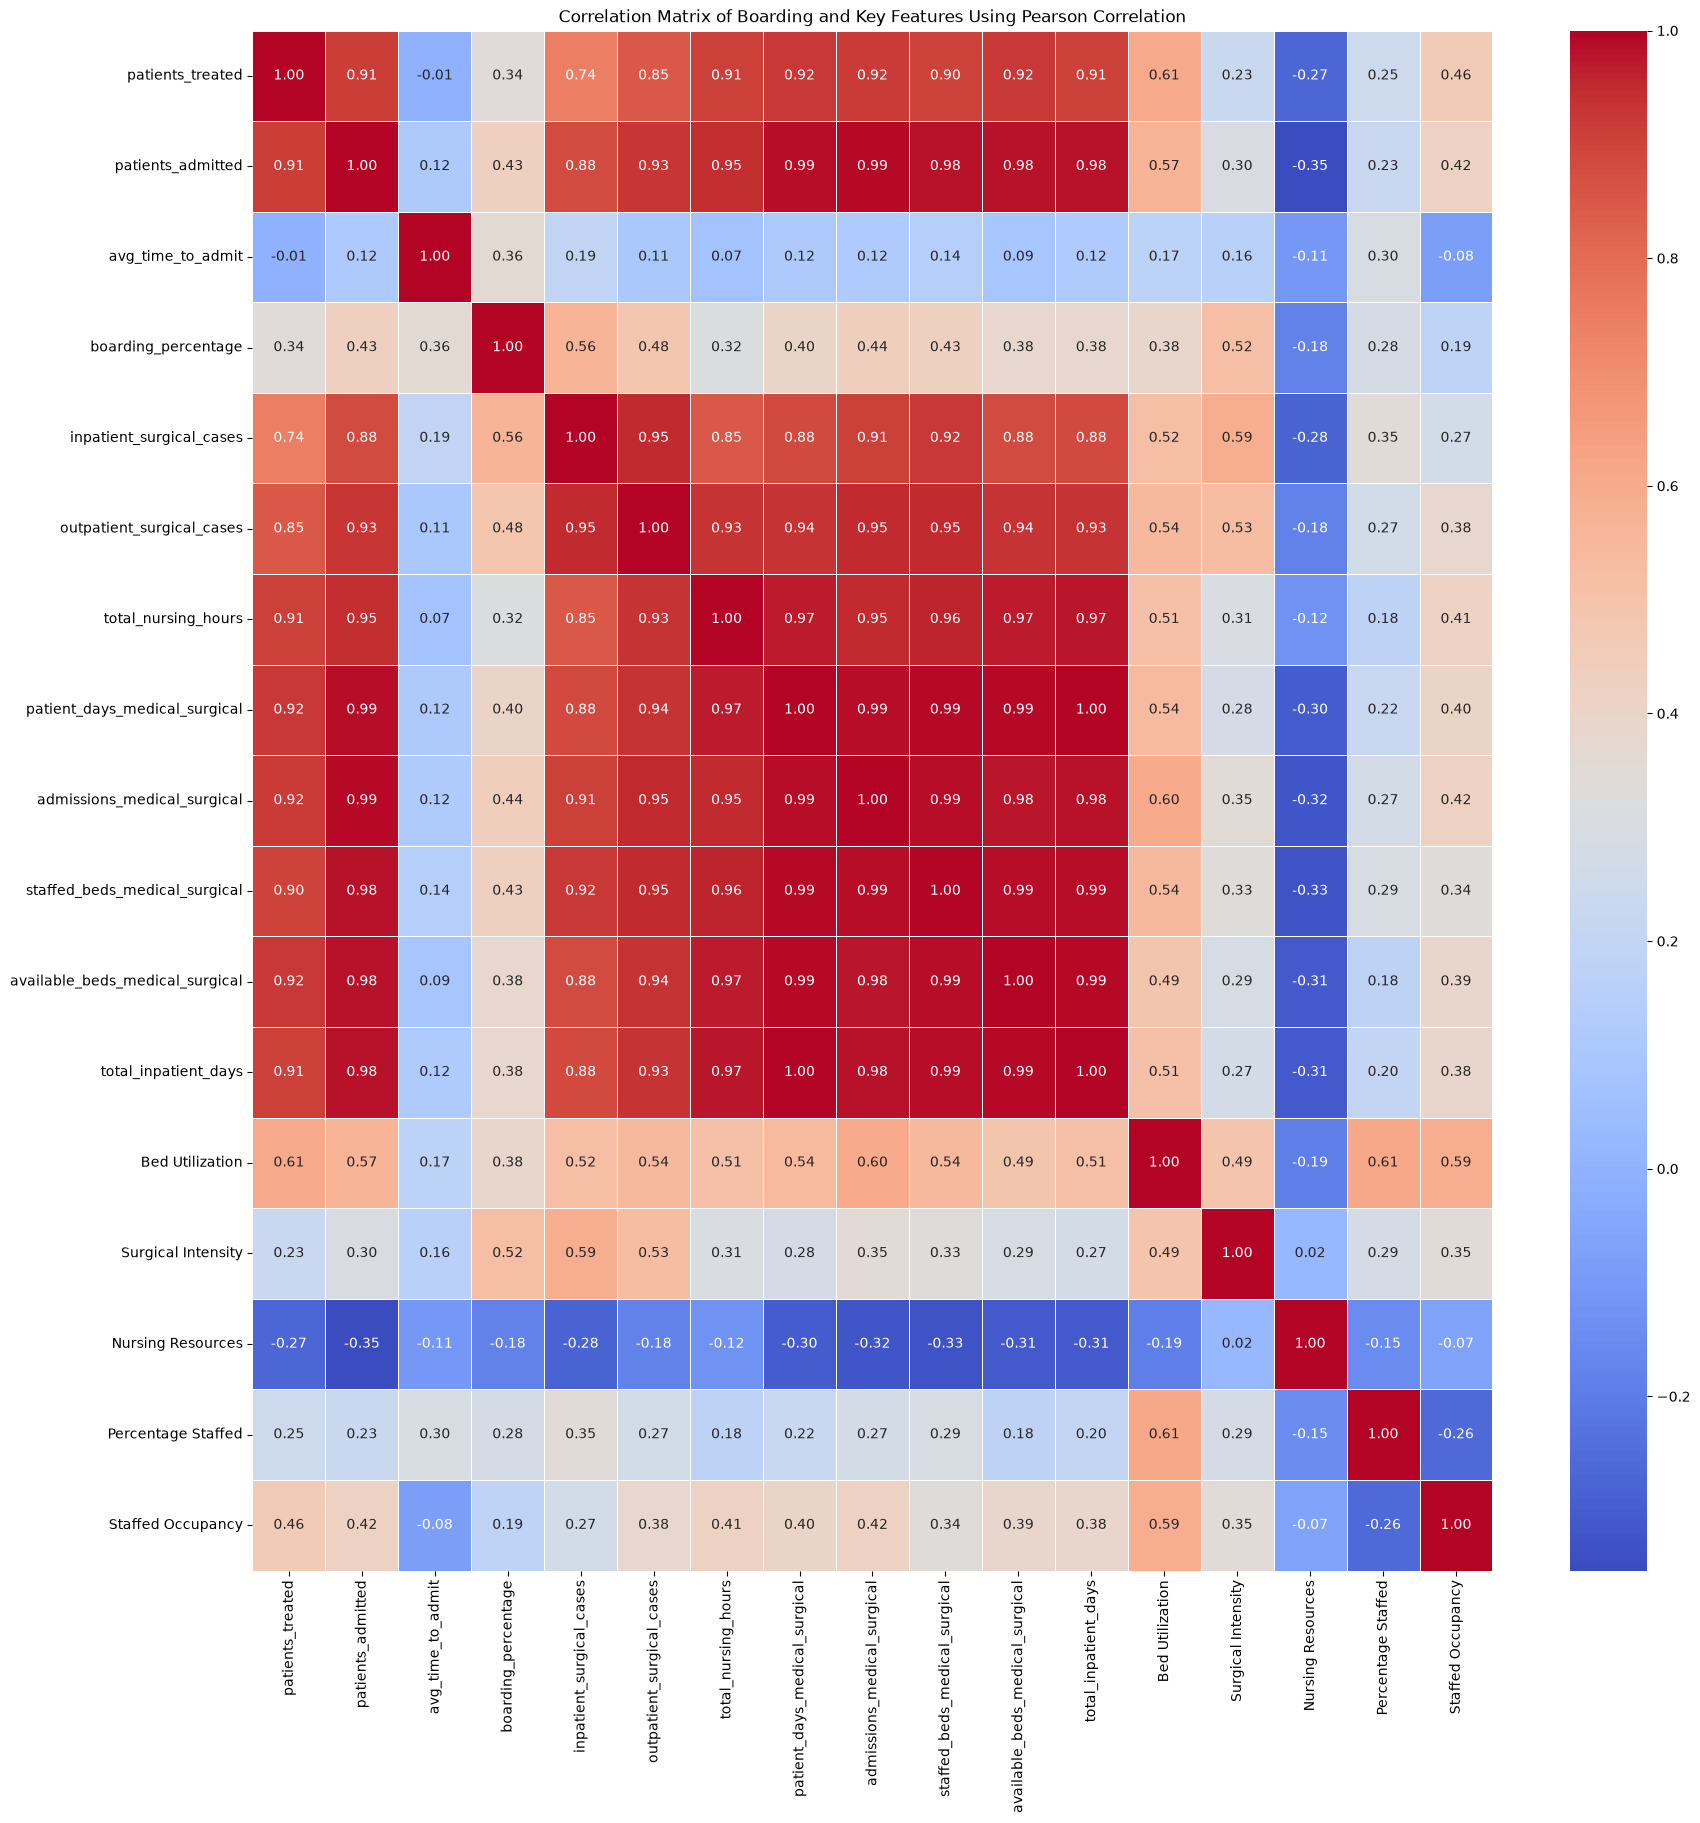

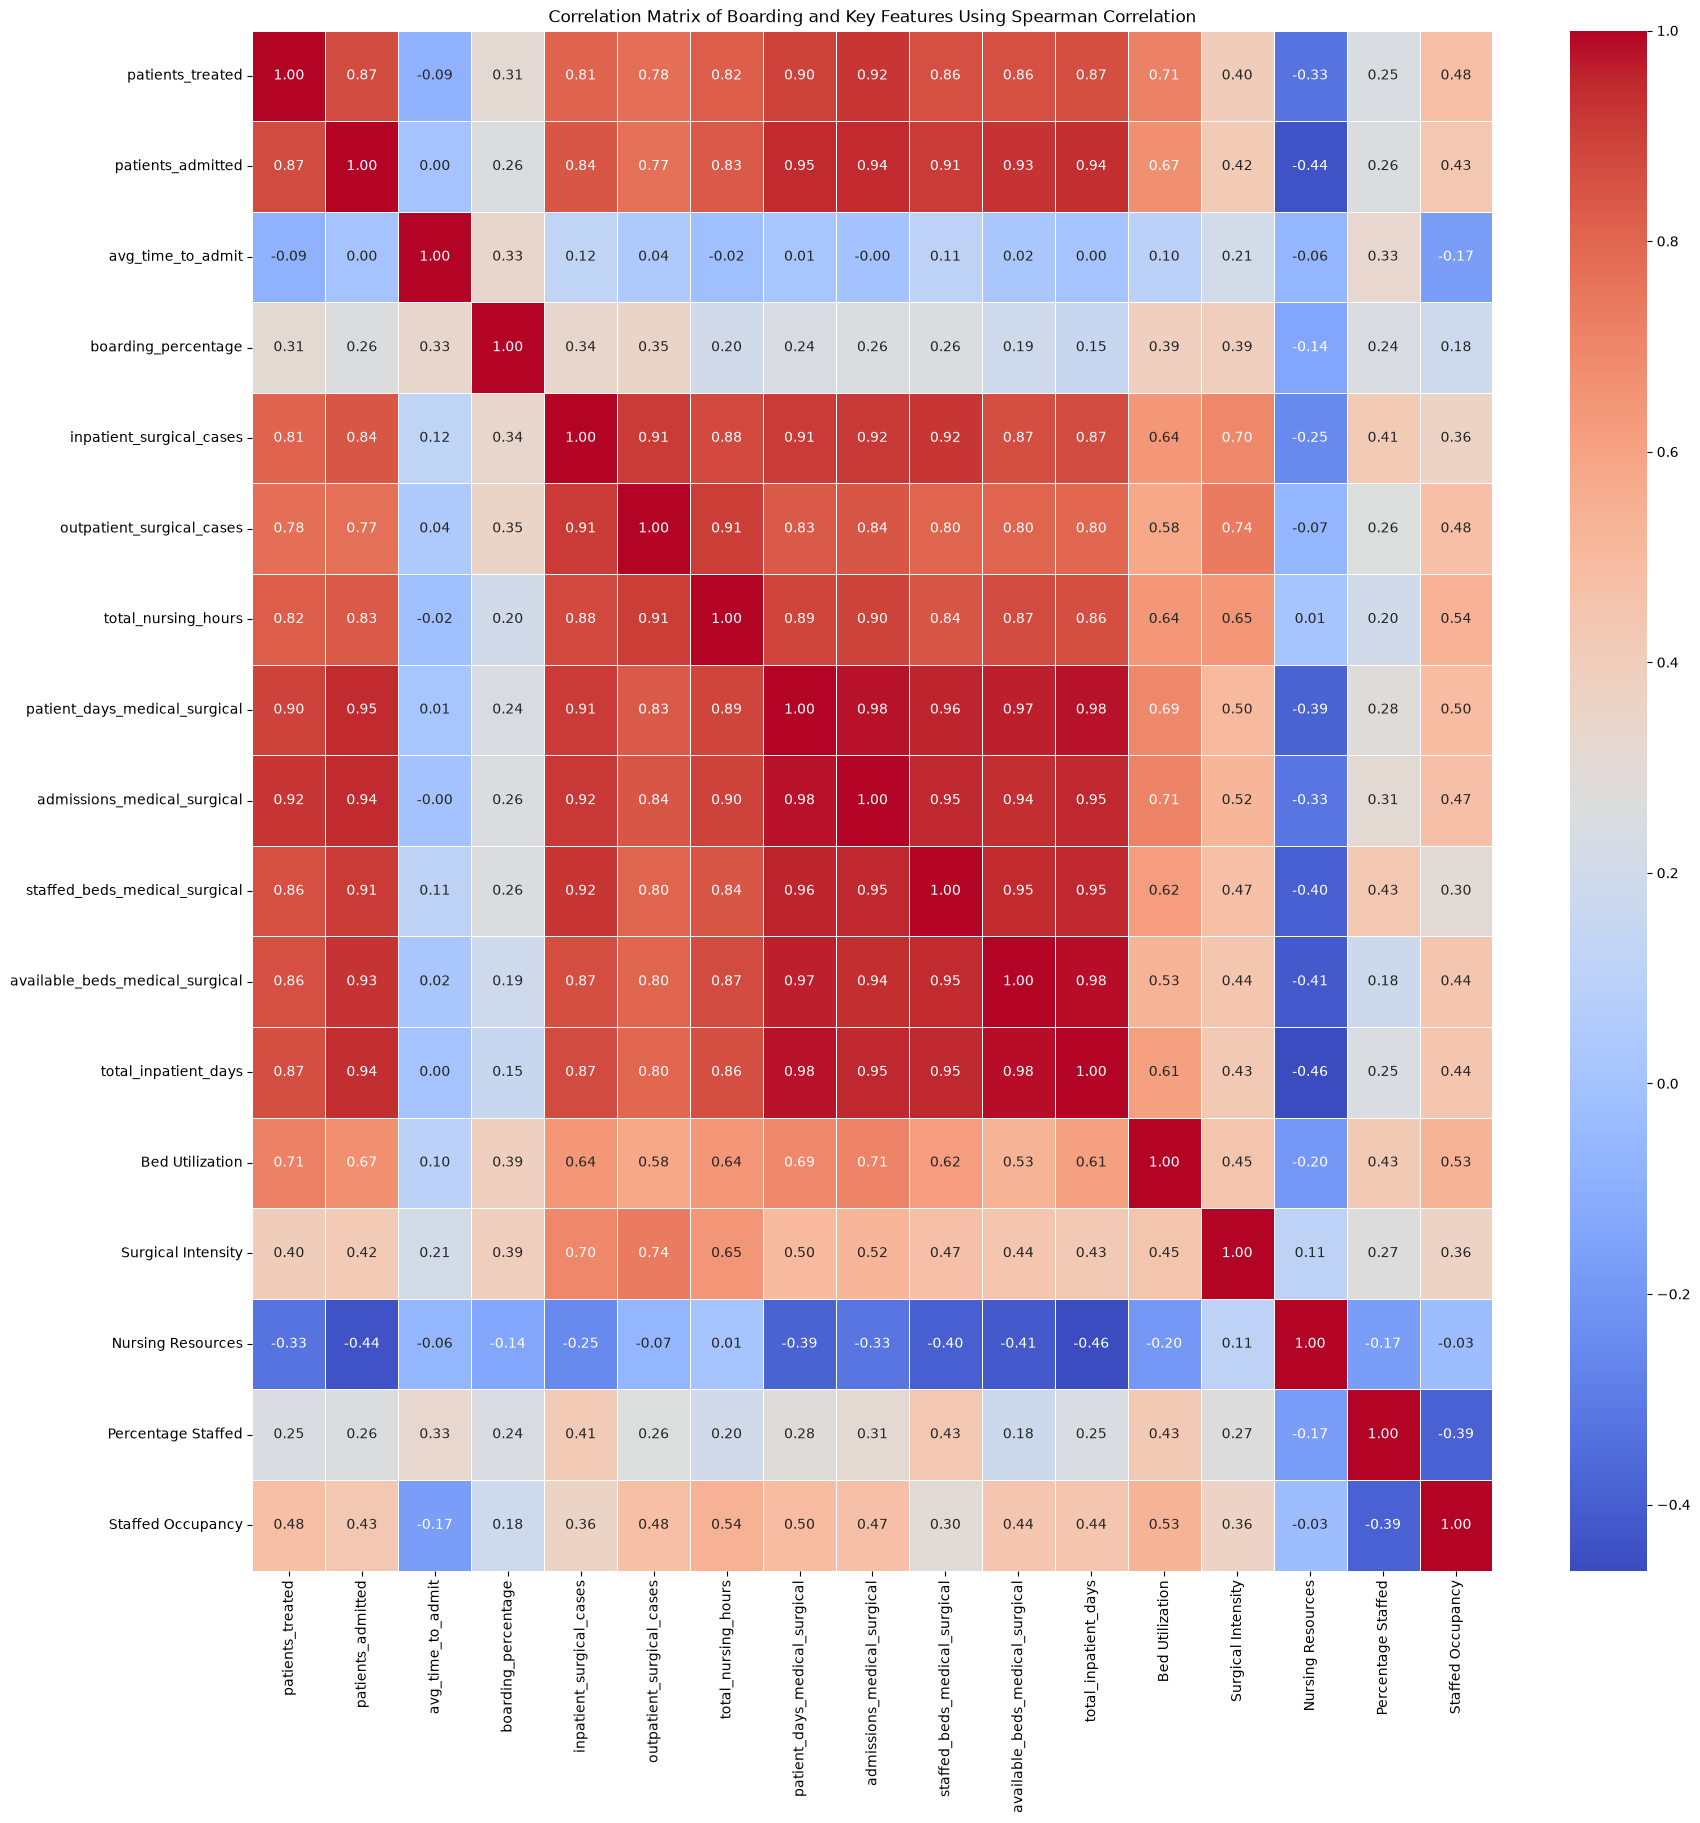

In [13]:
for correlation_method in ['pearson', 'spearman']:
    corr_matrix = main_data.iloc[:,1:].corr(method=correlation_method)
    plt.figure(figsize=(20, 20))
    sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt=".2f", linewidths=.5)
    plt.title(f'Correlation Matrix of Boarding and Key Features Using {correlation_method.capitalize()} Correlation')
    plt.savefig(f'./analysis_data/Processed Data/correlation_heatmap_{correlation_method}.png', bbox_inches='tight')
    plt.show()

In [14]:
spearman_corr = main_data[['Bed Utilization', 'Surgical Intensity', 'Nursing Resources', 'Percentage Staffed', 'Staffed Occupancy']]\
    .agg(lambda x: 'spearman rho: {:.2f} (p={:.4f})'.format(*spearmanr(x, main_data['boarding_percentage'], alternative='two-sided')))
pearson_corr = main_data[['Bed Utilization', 'Surgical Intensity', 'Nursing Resources', 'Percentage Staffed', 'Staffed Occupancy']]\
    .agg(lambda x: 'pearson r: {:.2f} (p={:.4f})'.format(*pearsonr(x, main_data['boarding_percentage'], alternative='two-sided')))
(spearman_corr + " " + pearson_corr).to_csv('./analysis_data/Processed Data/bivariate_correlations.csv', index=True)

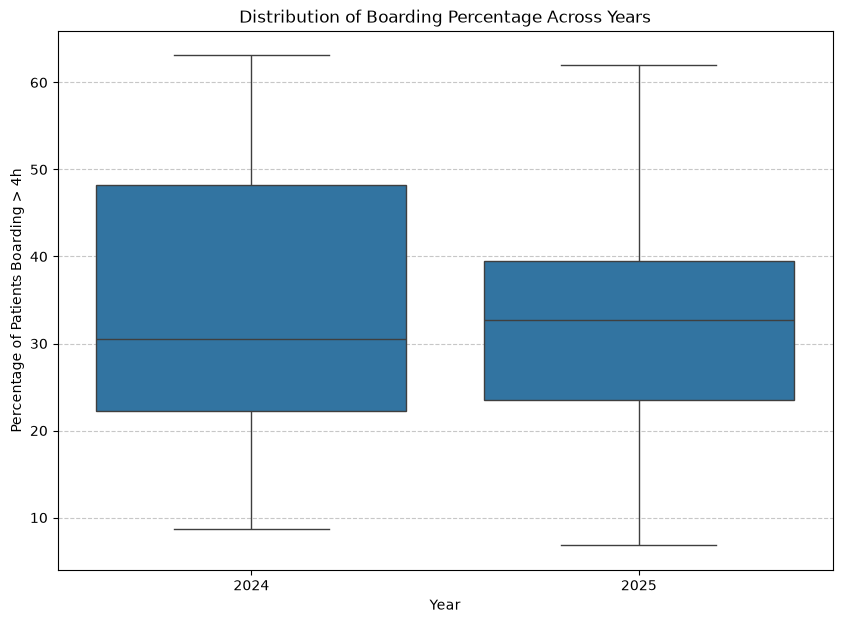

In [15]:
plt.figure(figsize=(10, 7))
sns.boxplot(x='year', y='boarding_percentage', data=main_data.reset_index())
plt.title('Distribution of Boarding Percentage Across Years')
plt.ylabel('Percentage of Patients Boarding > 4h')
plt.xlabel('Year')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.savefig('./analysis_data/Processed Data/boarding_year_boxplot.png', dpi=300, bbox_inches='tight')
plt.show()


In [16]:
compare_years = main_data.reset_index()[['year', 'boarding_percentage']]
ttest = stats.ttest_ind(
    compare_years[compare_years['year'] == 2024]['boarding_percentage'],
    compare_years[compare_years['year'] == 2025]['boarding_percentage'],
    alternative='two-sided'
)
print(f"T-test result for boarding percentage between 2024 and 2025: t-statistic = {ttest.statistic:.4f}, p-value = {ttest.pvalue:.4f}")
compare_years.groupby('year').describe()

T-test result for boarding percentage between 2024 and 2025: t-statistic = 0.2794, p-value = 0.7812


boarding_percentage                                                   \
                   count       mean        std  min     25%   50%     75%   
year                                                                        
2024                24.0  33.741667  16.244221  8.7  22.275  30.5  48.200   
2025                24.0  32.466667  15.363188  6.8  23.525  32.7  39.425   

            
       max  
year        
2024  63.1  
2025  62.0

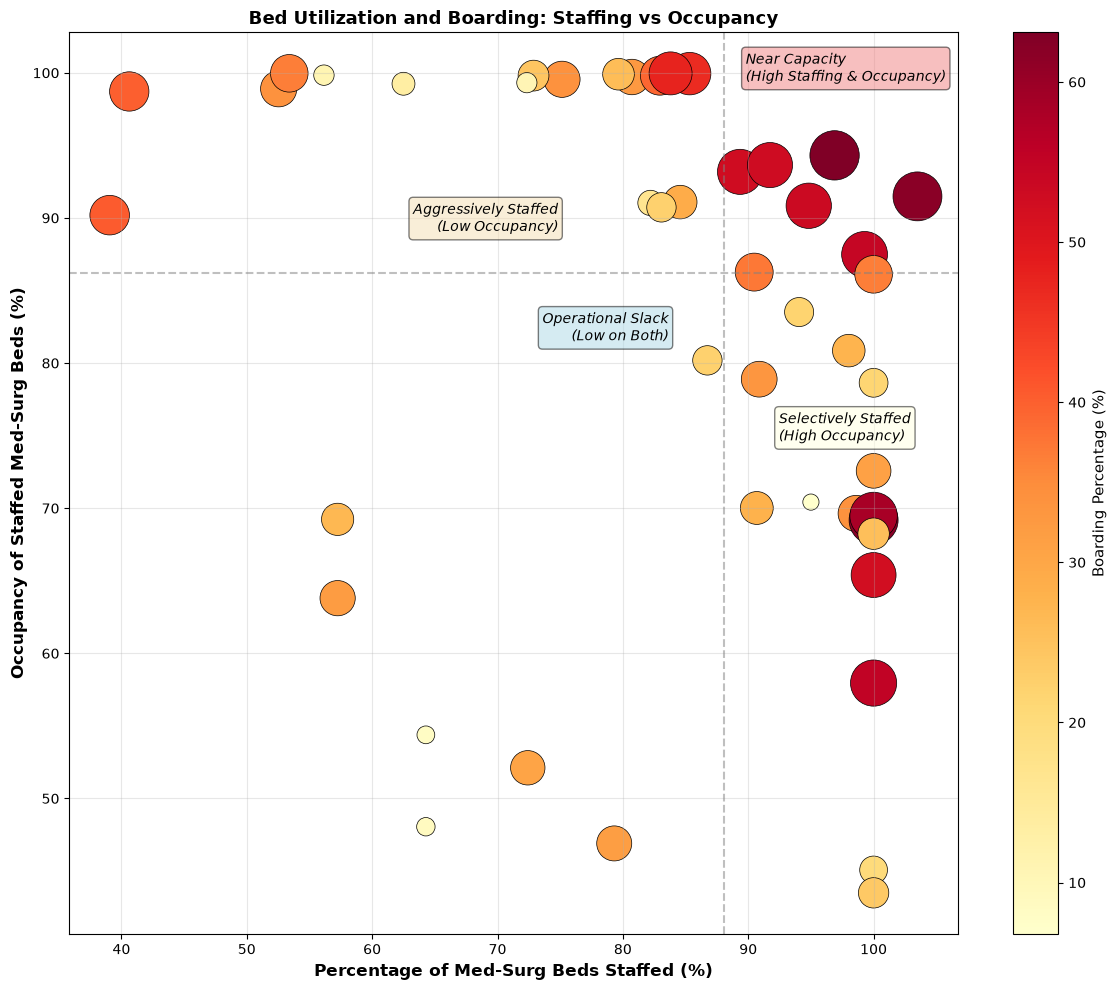

In [34]:
# Create scatter plot of staffed percentage vs occupancy with boarding percentage as point size
fig, ax = plt.subplots(figsize=(12, 10))
# Calculate medians for quadrant lines
med_x = main_data['Percentage Staffed'].median() * 100
med_y = main_data['Staffed Occupancy'].median() * 100
# Add dotted median lines
ax.axvline(med_x, color='gray', linestyle='--', linewidth=1.5, alpha=0.5)
ax.axhline(med_y, color='gray', linestyle='--', linewidth=1.5, alpha=0.5)
ax.grid(True, alpha=0.3)
# Scatter plot with boarding_percentage as size
scatter = ax.scatter(main_data['Percentage Staffed'] * 100, 
                     main_data['Staffed Occupancy'] * 100,
                     s=main_data['boarding_percentage'] * 20,  # scale for visibility
                     alpha=1, 
                     c=main_data['boarding_percentage'],
                     cmap='YlOrRd',
                     edgecolors='black',
                     linewidth=0.5)

# Add colorbar
cbar = plt.colorbar(scatter, ax=ax)
cbar.set_label('Boarding Percentage (%)', fontsize=11)

# Add quadrant labels
ax.text(med_x * 0.85, med_y * 1.03, 'Aggressively Staffed\n(Low Occupancy)', 
        fontsize=10, ha='right', va='bottom', style='italic', 
        bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.5))
ax.text(med_x * 1.02, med_y * 1.15, 'Near Capacity\n(High Staffing & Occupancy)', 
        fontsize=10, ha='left', va='bottom', style='italic',
        bbox=dict(boxstyle='round', facecolor='lightcoral', alpha=0.5))
ax.text(med_x * 0.95, med_y * 0.97, 'Operational Slack\n(Low on Both)', 
        fontsize=10, ha='right', va='top', style='italic',
        bbox=dict(boxstyle='round', facecolor='lightblue', alpha=0.5))
ax.text(med_x * 1.05, med_y * 0.89, 'Selectively Staffed\n(High Occupancy)', 
        fontsize=10, ha='left', va='top', style='italic',
        bbox=dict(boxstyle='round', facecolor='lightyellow', alpha=0.5))

ax.set_xlabel('Percentage of Med-Surg Beds Staffed (%)', fontsize=12, fontweight='bold')
ax.set_ylabel('Occupancy of Staffed Med-Surg Beds (%)', fontsize=12, fontweight='bold')
ax.set_title('Bed Utilization and Boarding: Staffing vs Occupancy', 
             fontsize=13, fontweight='bold')

plt.tight_layout()
plt.savefig('./analysis_data/Processed Data/staffing_occupancy_scatter.png', dpi=300, bbox_inches='tight')
plt.show()

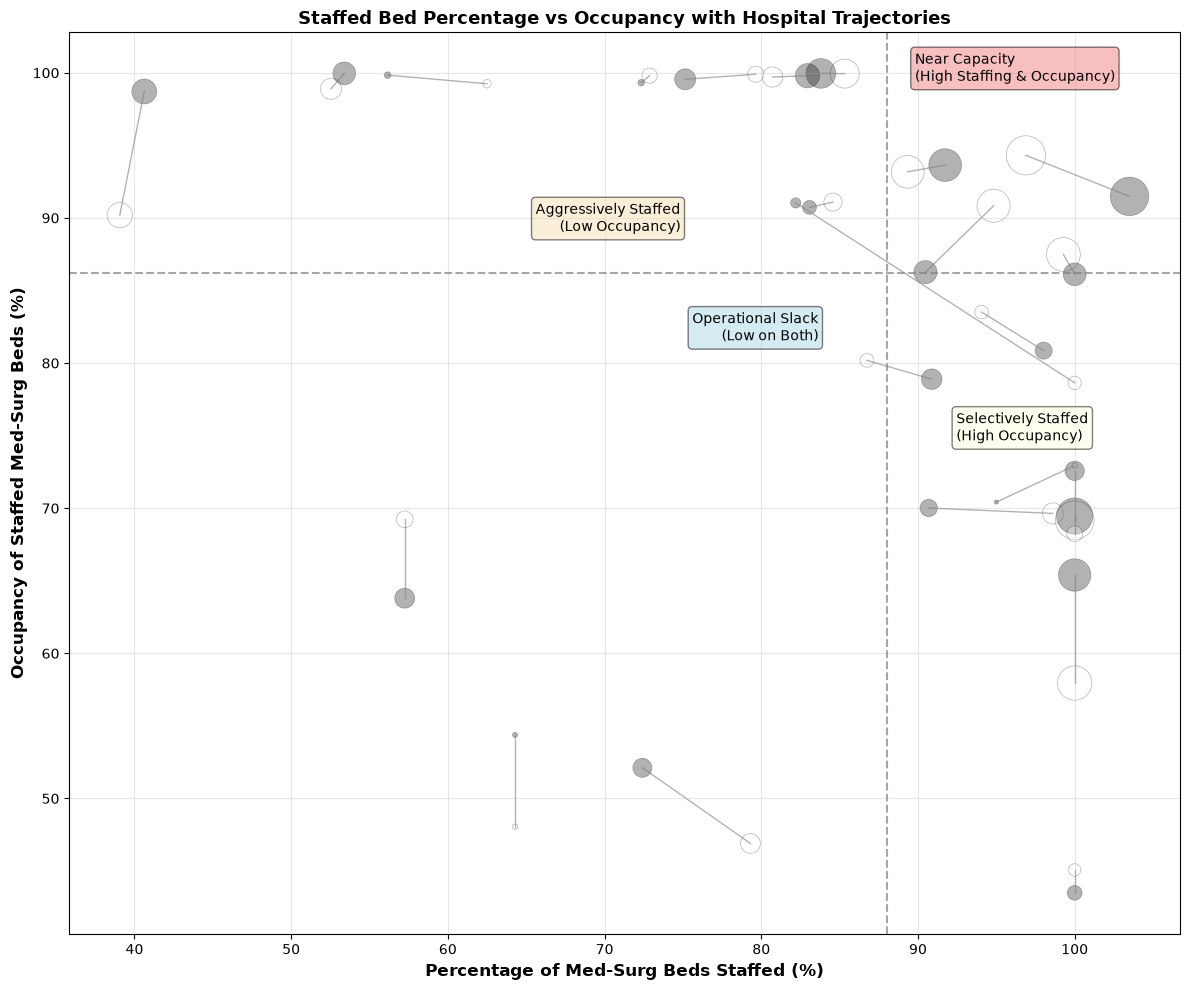

In [18]:
fig, ax = plt.subplots(figsize=(12, 10))

# Plot lines connecting the two years for each hospital
for hospital_slug, grp in main_data.reset_index().groupby('hospital_slug'):
    if len(grp) > 1:
        grp = grp.sort_values('year')
        ax.plot(grp['Percentage Staffed'] * 100,
                grp['Staffed Occupancy'] * 100,
                color='gray',
                linestyle='-',
                linewidth=1,
                alpha=0.6)

# Marker size approximating diameter from boarding percentage
sizes = (main_data['boarding_percentage'] ** 2) / 5

scatter = ax.scatter(main_data['Percentage Staffed'] * 100,
                     main_data['Staffed Occupancy'] * 100,
                     s=sizes,
                     c=main_data.reset_index()['year'],
                     cmap='binary',
                     alpha=0.3,
                     edgecolors='black',
                     linewidths=0.5)

med_x = main_data['Percentage Staffed'].median() * 100
med_y = main_data['Staffed Occupancy'].median() * 100

ax.axvline(med_x, color='gray', linestyle='--', linewidth=1.5, alpha=0.7)
ax.axhline(med_y, color='gray', linestyle='--', linewidth=1.5, alpha=0.7)

ax.text(med_x * 0.85, med_y * 1.03, 'Aggressively Staffed\n(Low Occupancy)',
        fontsize=10, ha='right', va='bottom',
        bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.5))
ax.text(med_x * 1.02, med_y * 1.15, 'Near Capacity\n(High Staffing & Occupancy)',
        fontsize=10, ha='left', va='bottom',
        bbox=dict(boxstyle='round', facecolor='lightcoral', alpha=0.5))
ax.text(med_x * 0.95, med_y * 0.97, 'Operational Slack\n(Low on Both)',
        fontsize=10, ha='right', va='top',
        bbox=dict(boxstyle='round', facecolor='lightblue', alpha=0.5))
ax.text(med_x * 1.05, med_y * 0.89, 'Selectively Staffed\n(High Occupancy)',
        fontsize=10, ha='left', va='top',
        bbox=dict(boxstyle='round', facecolor='lightyellow', alpha=0.5))

ax.set_xlabel('Percentage of Med-Surg Beds Staffed (%)', fontsize=12, fontweight='bold')
ax.set_ylabel('Occupancy of Staffed Med-Surg Beds (%)', fontsize=12, fontweight='bold')
ax.set_title('Staffed Bed Percentage vs Occupancy with Hospital Trajectories', fontsize=13, fontweight='bold')
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('./analysis_data/Processed Data/staffed_pct_vs_occupancy_trajectory_scatter.png', dpi=300, bbox_inches='tight')
plt.show()

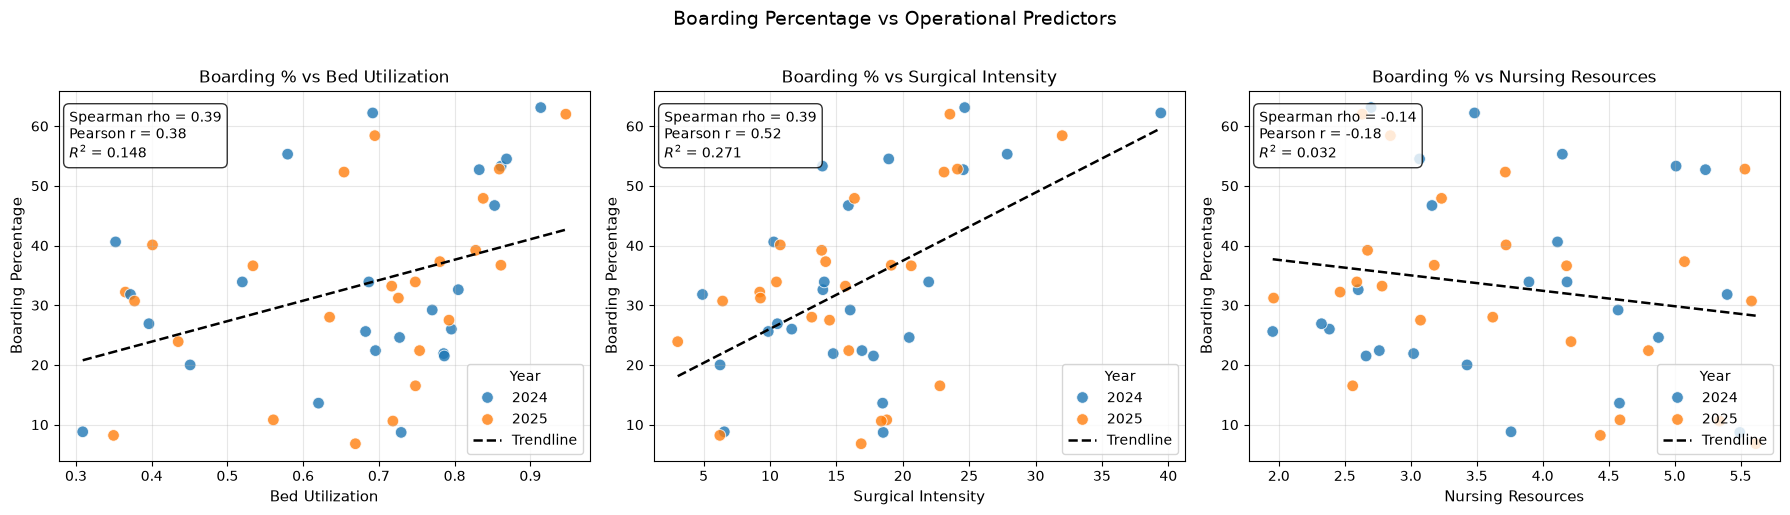

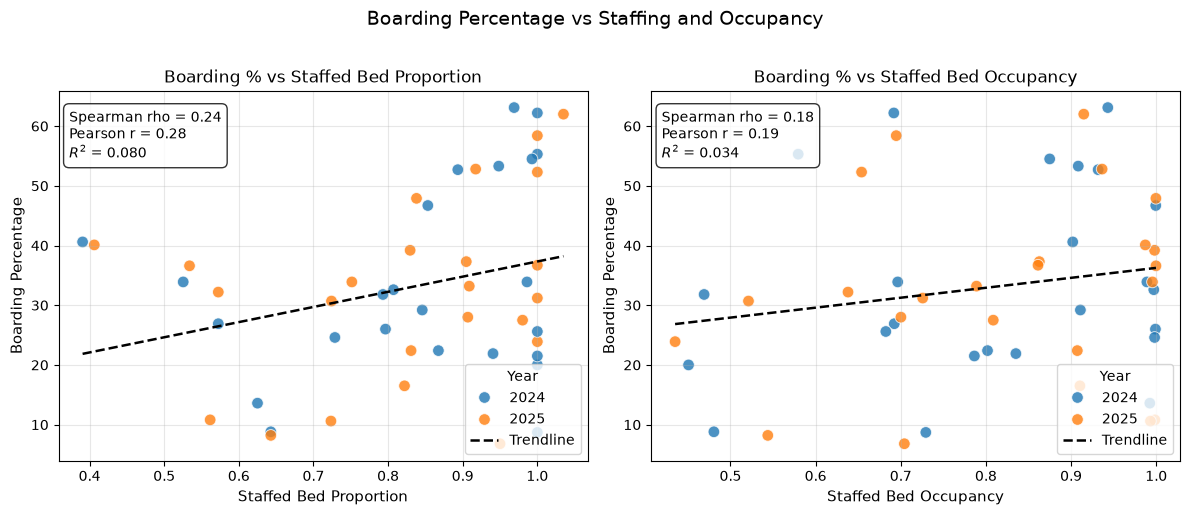

In [19]:
data = main_data.reset_index()

def plot_bivariate_scatter(vars_to_plot, fig_title, fig_path):
    fig, axes = plt.subplots(1, len(vars_to_plot), figsize=(6 * len(vars_to_plot), 5), sharey=False)
    if len(vars_to_plot) == 1:
        axes = [axes]

    for ax, (var_name, display_name) in zip(axes, vars_to_plot):
        subset = data[[var_name, 'boarding_percentage', 'year']].dropna()
        x = subset[var_name].astype(float)
        y = subset['boarding_percentage'].astype(float)

        # regression/trendline on full data
        lr = stats.linregress(x, y)
        x_line = np.linspace(x.min(), x.max(), 100)
        y_line = lr.intercept + lr.slope * x_line

        sns.scatterplot(
            data=subset,
            x=var_name,
            y='boarding_percentage',
            hue='year',
            palette='tab10',
            alpha=0.8,
            s=70,
            ax=ax
        )
        ax.plot(x_line, y_line, color='black', linestyle='--', linewidth=1.8, label='Trendline')

        rho, p_s = spearmanr(x, y)
        r, p_p = pearsonr(x, y)
        r2 = lr.rvalue ** 2
        p_linreg = lr.pvalue

        stats_text = (
            f"Spearman rho = {rho:.2f}\n"
            f"Pearson r = {r:.2f}\n"
            f"$R^2$ = {r2:.3f}"
        )

        ax.text(
            0.02, 0.95, stats_text,
            transform=ax.transAxes,
            fontsize=10,
            verticalalignment='top',
            bbox=dict(boxstyle='round,pad=0.4', facecolor='white', alpha=0.8)
        )

        ax.set_xlabel(display_name, fontsize=11)
        ax.set_ylabel('Boarding Percentage', fontsize=11)
        ax.set_title(f'Boarding % vs {display_name}', fontsize=12)
        ax.legend(title='Year', loc='lower right')
        ax.grid(alpha=0.3)

    fig.suptitle(fig_title, fontsize=14, y=1.02)
    fig.tight_layout()
    fig.savefig(fig_path, dpi=300, bbox_inches='tight')
    plt.show()

plot_bivariate_scatter(
    [
        ('Bed Utilization', 'Bed Utilization'),
        ('Surgical Intensity', 'Surgical Intensity'),
        ('Nursing Resources', 'Nursing Resources')
    ],
    'Boarding Percentage vs Operational Predictors',
    './analysis_data/Processed Data/boarding_vs_operational_predictors.png'
)

plot_bivariate_scatter(
    [
        ('Percentage Staffed', 'Staffed Bed Proportion'),
        ('Staffed Occupancy', 'Staffed Bed Occupancy')
    ],
    'Boarding Percentage vs Staffing and Occupancy',
    './analysis_data/Processed Data/boarding_vs_staffing_occupancy.png'
)

In [20]:
scaler = MinMaxScaler()
modeling_data = main_data.reset_index().set_index('CCEP_name')[['boarding_percentage', 'Percentage Staffed', 'Staffed Occupancy', 'Bed Utilization', 'Surgical Intensity', 'Nursing Resources']]
modeling_data_scaled = modeling_data.copy()
modeling_data_scaled[modeling_data.columns] = scaler.fit_transform(modeling_data)

In [21]:
def unscale_data(coef_table,scaler_obj, requires_unscaling):
  ret_dict = {}
  for var in coef_table.index:
    coef = coef_table.loc[var, 'Coef.']
    se = coef_table.loc[var, 'Std.Err.']
    p_value = coef_table.loc[var, 'P>|z|']
    if requires_unscaling:
      scale = scaler_obj.scale_[np.where(scaler_obj.feature_names_in_ == var)[0][0]]
      coef_unscaled = coef * scale
      se_unscaled = se * scale
      lower_unscaled = coef_unscaled - 1.96 * se_unscaled
      upper_unscaled = coef_unscaled + 1.96 * se_unscaled
      ret_dict[var] = {
          'coef': f"{coef_unscaled:.4f}",
          '95% CI': f"({lower_unscaled:.4f} - {upper_unscaled:.4f})",
          'p_value': "0.0001" if p_value < 0.0001 else f"{p_value:.4f}"
      }
    else:
      ret_dict[var] = {
          'coef': f"{coef:.4f}",
          '95% CI': f"({(coef - 1.96 * se):.4f} - {(coef + 1.96 * se):.4f})",
          'p_value': "0.0001" if p_value < 0.0001 else f"{p_value:.4f}"
      }
  return pd.DataFrame(ret_dict).T

def run_OLS(endog, exog, requires_unscaling = True):
  exog = sm.add_constant(exog) # Add a constant to the exogenous variables
  ols_results = OLS(endog, exog).fit(cov_type='cluster', cov_kwds={'groups': endog.index})
  return pd.Series({
    'Coefficients': unscale_data(ols_results.summary2().tables[1].iloc[1:], scaler, requires_unscaling),
    'Condition Number': f"{ols_results.condition_number:.2f}",
    'R-squared': f"{ols_results.rsquared:.4f}",
    'BIC': f"{ols_results.bic:.2f}",
    'Log-Likelihood Function': ols_results.llf
  })

In [22]:
print("Running OLS regression: boarding percentage vs Percentage Staffed, Staffed Occupancy, Surgical Intensity, and Nursing Resources...")
run_OLS(modeling_data_scaled['boarding_percentage'], modeling_data_scaled[['Percentage Staffed', 'Staffed Occupancy', 'Surgical Intensity', 'Nursing Resources']]).iloc[1:]

Running OLS regression: boarding percentage vs Percentage Staffed, Staffed Occupancy, Surgical Intensity, and Nursing Resources...


Condition Number              11.37
R-squared                    0.3221
BIC                           13.02
Log-Likelihood Function    3.166016
dtype: object

In [23]:
run_OLS(modeling_data_scaled['boarding_percentage'], modeling_data_scaled[['Percentage Staffed', 'Staffed Occupancy', 'Surgical Intensity', 'Nursing Resources']]).iloc[0]

,coef,95% CI,p_value
Percentage Staffed,0.2160,(-0.4054 - 0.8374),0.4957
Staffed Occupancy,0.0737,(-0.4218 - 0.5691),0.7708
Surgical Intensity,0.0183,(0.0085 - 0.0281),0.0002
Nursing Resources,-0.0428,(-0.1468 - 0.0612),0.4204


In [24]:
print("Running OLS regression: boarding percentage vs Bed Utilization, Surgical Intensity, and Nursing Resources...")
run_OLS(modeling_data_scaled['boarding_percentage'], modeling_data_scaled[['Bed Utilization', 'Surgical Intensity', 'Nursing Resources']]).iloc[1:]

Running OLS regression: boarding percentage vs Bed Utilization, Surgical Intensity, and Nursing Resources...


Condition Number               8.64
R-squared                    0.3193
BIC                            9.35
Log-Likelihood Function    3.065758
dtype: object

In [25]:
run_OLS(modeling_data_scaled['boarding_percentage'], modeling_data_scaled[['Bed Utilization', 'Surgical Intensity', 'Nursing Resources']]).iloc[0]

,coef,95% CI,p_value
Bed Utilization,0.1952,(-0.3594 - 0.7498),0.4902
Surgical Intensity,0.0181,(0.0072 - 0.0289),0.0011
Nursing Resources,-0.0427,(-0.1444 - 0.0590),0.4103


In [26]:
print("Runs for R-squared for individual predictors:")
for predictor in ['Bed Utilization', 'Surgical Intensity', 'Nursing Resources']:
    print(f"Predictor: {predictor}")
    print(run_OLS(modeling_data_scaled['boarding_percentage'], modeling_data_scaled[[predictor]]).iloc[2])

Runs for R-squared for individual predictors:
Predictor: Bed Utilization
0.1479
Predictor: Surgical Intensity
0.2714
Predictor: Nursing Resources
0.0323


In [27]:
# ============================================================
# 7. VARIANCE INFLATION FACTORS
# ============================================================
print('\n' + '=' * 72)
print('VARIANCE INFLATION FACTORS (pooled n = 48)')
print('=' * 72)
X_with_const = sm.add_constant(modeling_data_scaled[['Bed Utilization', 'Surgical Intensity', 'Nursing Resources']])  # Add a constant to the exogenous variables
for i, p in enumerate(['Bed Utilization', 'Surgical Intensity', 'Nursing Resources']):
    vif = variance_inflation_factor(X_with_const.values, i + 1)
    print(f'  VIF({p:<12s}) = {vif:.2f}')
print('\n' + '=' * 72)
print('VARIANCE INFLATION FACTORS SENSITIVITY ANALYSIS(pooled n = 48)')
print('=' * 72)
X_with_const = sm.add_constant(modeling_data_scaled[['Percentage Staffed', 'Staffed Occupancy', 'Surgical Intensity', 'Nursing Resources']])  # Add a constant to the exogenous variables
for i, p in enumerate(['Percentage Staffed', 'Staffed Occupancy', 'Surgical Intensity', 'Nursing Resources']):
    vif = variance_inflation_factor(X_with_const.values, i + 1)
    print(f'  VIF({p:<12s}) = {vif:.2f}')



VARIANCE INFLATION FACTORS (pooled n = 48)
  VIF(Bed Utilization) = 1.40
  VIF(Surgical Intensity) = 1.35
  VIF(Nursing Resources) = 1.06

VARIANCE INFLATION FACTORS SENSITIVITY ANALYSIS(pooled n = 48)
  VIF(Percentage Staffed) = 1.36
  VIF(Staffed Occupancy) = 1.39
  VIF(Surgical Intensity) = 1.40
  VIF(Nursing Resources) = 1.06


In [28]:
hospital_averaged_sensitivity_analysis = main_data.groupby('hospital_slug')[['boarding_percentage', 'Bed Utilization', 'Surgical Intensity', 'Nursing Resources']].mean()
hospital_averaged_sensitivity_analysis_scaled = pd.DataFrame(scaler.fit_transform(hospital_averaged_sensitivity_analysis), columns=hospital_averaged_sensitivity_analysis.columns, index=hospital_averaged_sensitivity_analysis.index)
run_OLS(hospital_averaged_sensitivity_analysis_scaled['boarding_percentage'], hospital_averaged_sensitivity_analysis_scaled[['Bed Utilization', 'Surgical Intensity', 'Nursing Resources']], requires_unscaling=True).iloc[1:]

Condition Number               7.88
R-squared                    0.3427
BIC                            8.76
Log-Likelihood Function    1.974013
dtype: object

In [29]:
run_OLS(hospital_averaged_sensitivity_analysis_scaled['boarding_percentage'], hospital_averaged_sensitivity_analysis_scaled[['Bed Utilization', 'Surgical Intensity', 'Nursing Resources']], requires_unscaling=True).iloc[0]

,coef,95% CI,p_value
Bed Utilization,0.1654,(-0.4264 - 0.7571),0.5839
Surgical Intensity,0.0195,(0.0081 - 0.0309),0.0008
Nursing Resources,-0.0459,(-0.1557 - 0.0639),0.4123
